# Optional Task — Calibration under Controlled Covariate Shift

**Stage 1 of the distribution-shift study.** This notebook extends Track 1's known-posterior synthetic problem. The training distribution is uniform on $[-1,1]$; the shifted test distribution changes $P(X)$ but leaves $P(Y\mid X)$, and hence $\eta(x)$, unchanged.

The comparison is between predictive-only training ($\lambda=1$) and end-to-end training ($\lambda=0.1$ and $0.05$). The two end-to-end values are included because the preceding Track 1 experiments identify them as useful settings; this is a controlled sensitivity comparison, not validation of a universally optimal weight.

**Interpretation:** under this deterministic covariate shift, conditional calibration given $X$ is directly assessed through $\mathbb{E}_{Q_X}|p(X)-\eta(X)|$. We also report label-based top-label ECE and a binned marginal-probability calibration gap. These are distinct quantities and should not be conflated.

## 1. Setup and configuration

The default run uses 30 seeds and an expanded capacity grid `CAPACITIES = [5, 10, 100, 120, 200, 300, 1000]`, and four objective weights `LAMBDAS = [0.05, 0.1, 0.5, 1.0]`.

In [12]:
import time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
import torch

torch.set_default_dtype(torch.float64)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_TRAIN = 100
N_TEST = 20000
N_SEEDS = 30
CAPACITIES = [5, 10, 100, 120, 200, 300, 1000]
LAMBDAS = [0.05, 0.1, 0.5, 1.0]
LR = 0.5
EPOCHS = 1200
BINS_SOFT = 15
BANDWIDTH = 0.08
EVAL_BINS = 10
SHIFT_ALPHA = 1.5
print("device:", DEVICE, "| seeds:", N_SEEDS, "| capacities:", CAPACITIES)

PALETTE_LAMBDA = {0.05: "#264653", 0.1: "#2a9d8f", 0.5: "#e9c46a", 1.0: "#e76f51"}
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

device: cpu | seeds: 30 | capacities: [5, 10, 100, 120, 200, 300, 1000]


## 2. Data-generating process and shift

The training and in-distribution test inputs follow $U[-1,1]$. For the shifted test set, we use the density $q(x)\propto \exp(\alpha x)$ on the same support. This changes the input density without changing the conditional label model. Keeping support fixed avoids confounding covariate shift with extrapolation beyond the training support.

Train-source mean X=0.002; ID test mean X=-0.004; shifted mean X=0.442
ID positive rate=0.496; shifted positive rate=0.688


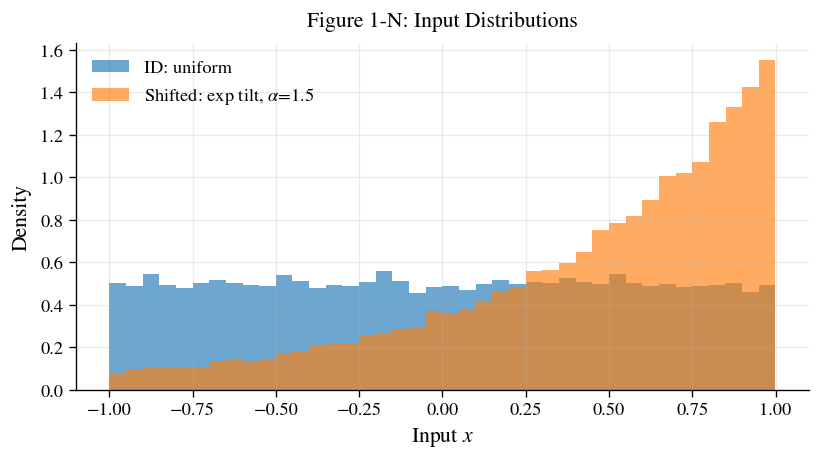

In [13]:
def sigmoid_np(z):
    z = np.clip(z, -40.0, 40.0)
    return 1.0 / (1.0 + np.exp(-z))

def eta(x):
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 * sigmoid_np(4.0 * np.sin(np.pi * x))

def sample_uniform(n, seed):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-1.0, 1.0, size=n)
    y = rng.binomial(1, eta(x)).astype(np.float64)
    return x, y

def sample_tilted(n, seed, alpha=SHIFT_ALPHA):
    rng = np.random.default_rng(seed)
    u = rng.uniform(0.0, 1.0, size=n)
    # Inverse CDF for density proportional to exp(alpha*x), x in [-1, 1].
    x = np.log(np.exp(-alpha) + u * (np.exp(alpha) - np.exp(-alpha))) / alpha
    y = rng.binomial(1, eta(x)).astype(np.float64)
    return x, y

xtr, ytr = sample_uniform(200000, 123)
xid, yid = sample_uniform(N_TEST, 999)
xshift, yshift = sample_tilted(N_TEST, 1001)
print(f"Train-source mean X={xtr.mean():.3f}; ID test mean X={xid.mean():.3f}; shifted mean X={xshift.mean():.3f}")
print(f"ID positive rate={yid.mean():.3f}; shifted positive rate={yshift.mean():.3f}")

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(xid, bins=40, density=True, alpha=.65, label="ID: uniform")
ax.hist(xshift, bins=40, density=True, alpha=.65, label=rf"Shifted: exp tilt, $\alpha$={SHIFT_ALPHA}")
ax.set_xlabel("Input $x$", labelpad=4)
ax.set_ylabel("Density", labelpad=5)
ax.set_title("Figure 1-N: Input Distributions", pad=10)
ax.legend(frameon=False, loc="best")
ax.tick_params(axis="both", which="major", length=4, width=0.8)
plt.tight_layout()
fig.savefig("Figure_1N_input_distributions.pdf", format="pdf", bbox_inches="tight")
plt.show()

## 3. Model and training objectives

The model is the same logistic Legendre-basis classifier used in Track 1. The soft-bin penalty follows the same construction as the earlier notebooks; the bin-membership weights are detached during differentiation, matching the straight-through approximation documented in Chapter 4 o the report. The training loss is $\lambda \mathcal E+(1-\lambda)\mathcal C_{\mathrm{soft}}$, so $\lambda=1$ is the predictive-only baseline.

In [14]:
def legendre_design(x, degree):
    x = np.asarray(x, dtype=np.float64)
    phi = np.empty((x.size, degree + 1), dtype=np.float64)
    phi[:, 0] = 1.0
    if degree >= 1: phi[:, 1] = x
    for k in range(2, degree + 1):
        phi[:, k] = ((2*k-1)*x*phi[:, k-1] - (k-1)*phi[:, k-2]) / k
    return phi

def soft_ece_torch(p, y, bins=BINS_SOFT, h=BANDWIDTH):
    centers = torch.linspace(0.5/bins, 1.0-0.5/bins, bins, dtype=p.dtype, device=p.device)
    logits = -((p[:, None] - centers[None, :])**2) / (2*h*h)
    w = torch.softmax(logits, dim=1).detach()  # straight-through assignment approximation
    mass = w.mean(dim=0)
    pbar = (w * p[:, None]).sum(dim=0) / (w.sum(dim=0) + 1e-12)
    ybar = (w * y[:, None]).sum(dim=0) / (w.sum(dim=0) + 1e-12)
    return torch.sum(mass * (pbar-ybar)**2)

def train_model(x, y, degree, lam, seed):
    torch.manual_seed(seed)
    phi = torch.tensor(legendre_design(x, degree), device=DEVICE)
    yt = torch.tensor(y, device=DEVICE)
    theta = torch.nn.Parameter(torch.randn(degree+1, device=DEVICE) * 0.1)
    opt = torch.optim.SGD([theta], lr=LR)
    for _ in range(EPOCHS):
        opt.zero_grad()
        p = torch.sigmoid(torch.clamp(phi @ theta, -30, 30))
        p_clip = torch.clamp(p, 1e-8, 1-1e-8)
        ce = -(yt*torch.log(p_clip) + (1-yt)*torch.log(1-p_clip)).mean()
        if lam < 1.0:
            cal = soft_ece_torch(p, yt)
            loss = (1-lam)*cal + lam*ce
        else:
            loss = ce
        loss.backward(); opt.step()
    return theta.detach().cpu().numpy()

# Cache test design matrices once. This avoids rebuilding large matrices for every seed.
PHI_TEST = {
    m: {
        "id": torch.tensor(legendre_design(xid, m), device=DEVICE),
        "shift": torch.tensor(legendre_design(xshift, m), device=DEVICE),
    }
    for m in CAPACITIES
}

def predict(theta, x=None, phi=None):
    if phi is None:
        phi = torch.tensor(legendre_design(x, len(theta)-1), device=DEVICE)
    with torch.no_grad():
        return torch.sigmoid(torch.clamp(phi @ torch.tensor(theta, device=DEVICE), -30, 30)).cpu().numpy()

## 4. Evaluation metrics

- **Top-label ECE:** compares confidence $\max(p,1-p)$ with the correctness of the thresholded class prediction. It is label-based and estimated with fixed-width confidence bins.
- **Marginal probability calibration gap:** bins the predicted probability and compares each bin's mean prediction with its mean true posterior $\eta(X)$. This removes Bernoulli label noise from the calibration diagnostic.
- **Conditional calibration error:** $\mathbb{E}_{Q_X}|p(X)-\eta(X)|$. Since $P(Y=1\mid X)=\eta(X)$ remains fixed, this directly measures the conditional probability mismatch under the test input distribution.
- **Posterior MSE:** $\mathbb{E}_{Q_X}(p(X)-\eta(X))^2$.

The latter two are distribution-weighted: they can change under covariate shift even though the conditional label mechanism is unchanged.

In [15]:
def ece_top_label(p, y, n_bins=15):
    conf = np.maximum(p, 1-p)
    pred = (p >= 0.5).astype(int)
    correct = (pred == y).astype(float)
    edges = np.linspace(0.5, 1.0, n_bins+1)
    total = len(p); ece = 0.0
    for j in range(n_bins):
        mask = (conf >= edges[j]) & (conf < edges[j+1] if j < n_bins-1 else conf <= edges[j+1])
        if mask.any(): ece += mask.mean() * abs(correct[mask].mean() - conf[mask].mean())
    return float(ece)

def marginal_calibration_gap(p, x, n_bins=15):
    truth = eta(x)
    edges = np.linspace(0.0, 1.0, n_bins+1)
    gap = 0.0
    for j in range(n_bins):
        mask = (p >= edges[j]) & (p < edges[j+1] if j < n_bins-1 else p <= edges[j+1])
        if mask.any(): gap += mask.mean() * abs(truth[mask].mean() - p[mask].mean())
    return float(gap)

def evaluate(theta, x, y, phi=None):
    p = predict(theta, x, phi=phi); truth = eta(x)
    p_clip = np.clip(p, 1e-12, 1.0 - 1e-12)
    cross_entropy = -np.mean(y * np.log(p_clip) + (1.0 - y) * np.log(1.0 - p_clip))
    return {
        "ece_top": ece_top_label(p, y),
        "marginal_calibration_gap": marginal_calibration_gap(p, x),
        "conditional_abs_error": float(np.mean(np.abs(p-truth))),
        "mse_eta": float(np.mean((p-truth)**2)),
        "brier": float(np.mean((p-y)**2)),
        "cross_entropy": float(cross_entropy),
        "mean_prediction": float(np.mean(p)),
        "mean_eta": float(np.mean(truth)),
    }

# Sanity check: oracle predictions have zero posterior error.
assert np.mean((eta(xid)-eta(xid))**2) == 0.0
print("Metric sanity check passed.")

Metric sanity check passed.


## 5. Multi-seed experiment

For each seed, capacity, and objective weight, the same training sample and initialization seed are used across all objective weights. Each fitted model is evaluated on the same in-distribution and shifted test inputs. This pairing reduces noise in method comparisons. The objective weight `lambda` weights the predictive cross-entropy term; the soft calibration penalty has weight `1 - lambda`, so smaller values emphasize calibration more strongly.

In [16]:
start = time.time()
rows = []
for seed in range(1, N_SEEDS+1):
    x_train, y_train = sample_uniform(N_TRAIN, 10000+seed)
    for m in CAPACITIES:
        for lam in LAMBDAS:
            theta = train_model(x_train, y_train, m, lam, seed=20000+seed)
            for split, (xx, yy) in {"id": (xid, yid), "shift": (xshift, yshift)}.items():
                met = evaluate(theta, xx, yy, phi=PHI_TEST[m][split])
                rows.append({"seed": seed, "m": m, "lambda": lam, "split": split, **met})
    if seed % 5 == 0: print(f"completed seed {seed}/{N_SEEDS} ({time.time()-start:.1f}s)")
results = pd.DataFrame(rows)
summary = results.groupby(["split","m","lambda"]).agg({
    "ece_top":["mean","std"], "marginal_calibration_gap":["mean","std"],
    "conditional_abs_error":["mean","std"], "mse_eta":["mean","std"], "brier":["mean","std"],
    "cross_entropy":["mean","std"]
}).round(4)

display(summary)

results.to_csv("track1_covariate_shift_results.csv", index=False)
results.to_excel("track1_covariate_shift_results.xlsx", index=False)

completed seed 5/30 (172.3s)
completed seed 10/30 (336.7s)
completed seed 15/30 (506.6s)
completed seed 20/30 (679.3s)
completed seed 25/30 (851.3s)
completed seed 30/30 (1022.5s)


ece_top         marginal_calibration_gap          \
                     mean     std                     mean     std   
split m    lambda                                                    
id    5    0.05    0.0456  0.0190                   0.0519  0.0198   
           0.10    0.0424  0.0177                   0.0496  0.0186   
           0.50    0.0471  0.0201                   0.0573  0.0215   
           1.00    0.0480  0.0203                   0.0589  0.0226   
      10   0.05    0.0448  0.0165                   0.0526  0.0195   
           0.10    0.0456  0.0165                   0.0522  0.0200   
           0.50    0.0620  0.0161                   0.0711  0.0210   
           1.00    0.0683  0.0176                   0.0772  0.0216   
      100  0.05    0.0516  0.0153                   0.0566  0.0196   
           0.10    0.0509  0.0126                   0.0594  0.0187   
           0.50    0.0864  0.0134                   0.0947  0.0157   
           1.00    0.1200  0.0151                   0.1251  0.0166   
      120  0.05    0.0510  0.0144                   0.0571  0.0198   
           0.10    0.0503  0.0132                   0.0590  0.0192   
           0.50    0.0867  0.0133                   0.0936  0.0158   
           1.00    0.1203  0.0167                   0.1264  0.0161   
      200  0.05    0.0503  0.0143                   0.0569  0.0194   
           0.10    0.0501  0.0128                   0.0592  0.0185   
           0.50    0.0870  0.0150                   0.0931  0.0171   
           1.00    0.1230  0.0157                   0.1280  0.0156   
      300  0.05    0.0504  0.0143                   0.0577  0.0189   
           0.10    0.0506  0.0131                   0.0594  0.0183   
           0.50    0.0858  0.0153                   0.0924  0.0177   
           1.00    0.1216  0.0146                   0.1259  0.0154   
      1000 0.05    0.0505  0.0131                   0.0585  0.0191   
           0.10    0.0503  0.0121                   0.0597  0.0188   
           0.50    0.0827  0.0142                   0.0893  0.0169   
           1.00    0.1115  0.0150                   0.1167  0.0155   
shift 5    0.05    0.0475  0.0247                   0.0551  0.0241   
           0.10    0.0463  0.0250                   0.0569  0.0233   
           0.50    0.0534  0.0271                   0.0660  0.0259   
           1.00    0.0537  0.0277                   0.0678  0.0265   
      10   0.05    0.0486  0.0204                   0.0555  0.0214   
           0.10    0.0527  0.0204                   0.0591  0.0236   
           0.50    0.0696  0.0229                   0.0811  0.0282   
           1.00    0.0765  0.0253                   0.0887  0.0307   
      100  0.05    0.0530  0.0197                   0.0579  0.0218   
           0.10    0.0541  0.0195                   0.0640  0.0220   
           0.50    0.0968  0.0170                   0.1157  0.0215   
           1.00    0.1308  0.0171                   0.1490  0.0213   
      120  0.05    0.0521  0.0199                   0.0582  0.0212   
           0.10    0.0540  0.0192                   0.0641  0.0215   
           0.50    0.0970  0.0171                   0.1150  0.0209   
           1.00    0.1316  0.0189                   0.1488  0.0200   
      200  0.05    0.0508  0.0198                   0.0580  0.0213   
           0.10    0.0543  0.0188                   0.0645  0.0207   
           0.50    0.0956  0.0178                   0.1139  0.0192   
           1.00    0.1326  0.0171                   0.1468  0.0178   
      300  0.05    0.0512  0.0197                   0.0586  0.0215   
           0.10    0.0535  0.0198                   0.0646  0.0209   
           0.50    0.0954  0.0177                   0.1119  0.0191   
           1.00    0.1304  0.0165                   0.1435  0.0171   
      1000 0.05    0.0506  0.0199                   0.0589  0.0222   
           0.10    0.0542  0.0192                   0.0649  0.0212   
           0.50    0.0912  0

## 6. Robustness gaps and paired comparisons

For lower-is-better metrics, the signed robustness gap is $M_{\mathrm{shift}}-M_{\mathrm{ID}}$; positive values indicate deterioration. We report it descriptively for each objective weight and capacity. Paired tests compare each end-to-end setting $\lambda \in \{0.05, 0.1, 0.5\}$ with the baseline $(\lambda = 1.0)$ separately on the ID and shifted test distributions. The comparisons are corrected with Bonferroni adjustment.

In [17]:
gap_metrics = ["ece_top", "marginal_calibration_gap", "conditional_abs_error", "mse_eta", "brier", "cross_entropy"]
wide = results.pivot(index=["seed","m","lambda"], columns="split", values=gap_metrics)
gap_rows=[]
for m in CAPACITIES:
    for lam in LAMBDAS:
        sub=results[(results.m==m)&(results["lambda"]==lam)]
        for metric in gap_metrics:
            vals=sub.pivot(index="seed",columns="split",values=metric)
            gap_rows.append({"m":m,"lambda":lam,"metric":metric,
                             "id_mean":vals["id"].mean(),"shift_mean":vals["shift"].mean(),
                             "robustness_gap":(vals["shift"]-vals["id"]).mean(),
                             "gap_sd":(vals["shift"]-vals["id"]).std()})
gap_table=pd.DataFrame(gap_rows).round(4)
display(gap_table)

# Paired baseline comparisons: lambda 0.05, 0.1 and 0.5 versus lambda 1, within each split.
test_rows=[]
for m in CAPACITIES:
    for split in ["id","shift"]:
        for metric in ["ece_top","marginal_calibration_gap","conditional_abs_error","mse_eta","brier", "cross_entropy"]:
            pivot=results[(results.m==m)&(results.split==split)].pivot(index="seed",columns="lambda",values=metric)
            for lam in [0.05,0.1,0.5]:
                stat=wilcoxon(pivot[lam],pivot[1.0],alternative="two-sided",zero_method="wilcox")
                test_rows.append({"m":m,"split":split,"metric":metric,"comparison":f"lambda={lam} vs 1.0","p_raw":stat.pvalue})
tests=pd.DataFrame(test_rows)
tests["p_bonf"]=(tests.p_raw*len(tests)).clip(upper=1.0)
tests["significant_0.05"] = tests.p_bonf < 0.05
display(tests.round(5))

tests.to_csv("track1_covariate_shift_paired_tests.csv",index=False)
tests.to_excel("track1_covariate_shift_paired_tests.xlsx",index=False)

,m,lambda,metric,id_mean,shift_mean,robustness_gap,gap_sd
0,5,0.05,ece_top,0.0456,0.0475,0.0019,0.0144
1,5,0.05,marginal_calibration_gap,0.0519,0.0551,0.0032,0.0159
2,5,0.05,conditional_abs_error,0.0666,0.0706,0.0039,0.0125
3,5,0.05,mse_eta,0.0085,0.0097,0.0012,0.0033
4,5,0.05,brier,0.1545,0.1601,0.0057,0.0030
...,...,...,...,...,...,...,...
163,1000,1.00,marginal_calibration_gap,0.1167,0.1320,0.0153,0.0112
164,1000,1.00,conditional_abs_error,0.1477,0.1541,0.0064,0.0106
165,1000,1.00,mse_eta,0.0390,0.0418,0.0028,0.0075
166,1000,1.00,brier,0.1846,0.1924,0.0077,0.0080


,m,split,metric,comparison,p_raw,p_bonf,significant_0.05
0,5,id,ece_top,lambda=0.05 vs 1.0,0.52911,1.00000,False
1,5,id,ece_top,lambda=0.1 vs 1.0,0.01745,1.00000,False
2,5,id,ece_top,lambda=0.5 vs 1.0,0.01853,1.00000,False
3,5,id,marginal_calibration_gap,lambda=0.05 vs 1.0,0.02085,1.00000,False
4,5,id,marginal_calibration_gap,lambda=0.1 vs 1.0,0.00003,0.00768,True
...,...,...,...,...,...,...,...
247,1000,shift,brier,lambda=0.1 vs 1.0,0.00000,0.00000,True
248,1000,shift,brier,lambda=0.5 vs 1.0,0.00000,0.00000,True
249,1000,shift,cross_entropy,lambda=0.05 vs 1.0,0.00000,0.00000,True
250,1000,shift,cross_entropy,lambda=0.1 vs 1.0,0.00000,0.00000,True


## 7. Visual summary

Figure 1-O shows six metrics in a 3 × 2 layout. Line color identifies the objective weight, while line style and marker distinguish the test distribution: solid line with circle markers for ID, and dotted line with x markers for shifted data. Error bars show standard deviation across seeds. The shifted distribution changes the weighting over $x$, so the ID-to-shift change in posterior error is meaningful even though $\eta(x)$ is unchanged. A smaller robustness gap is not automatically better if the shifted metric itself is worse; report both the absolute values and the gap.

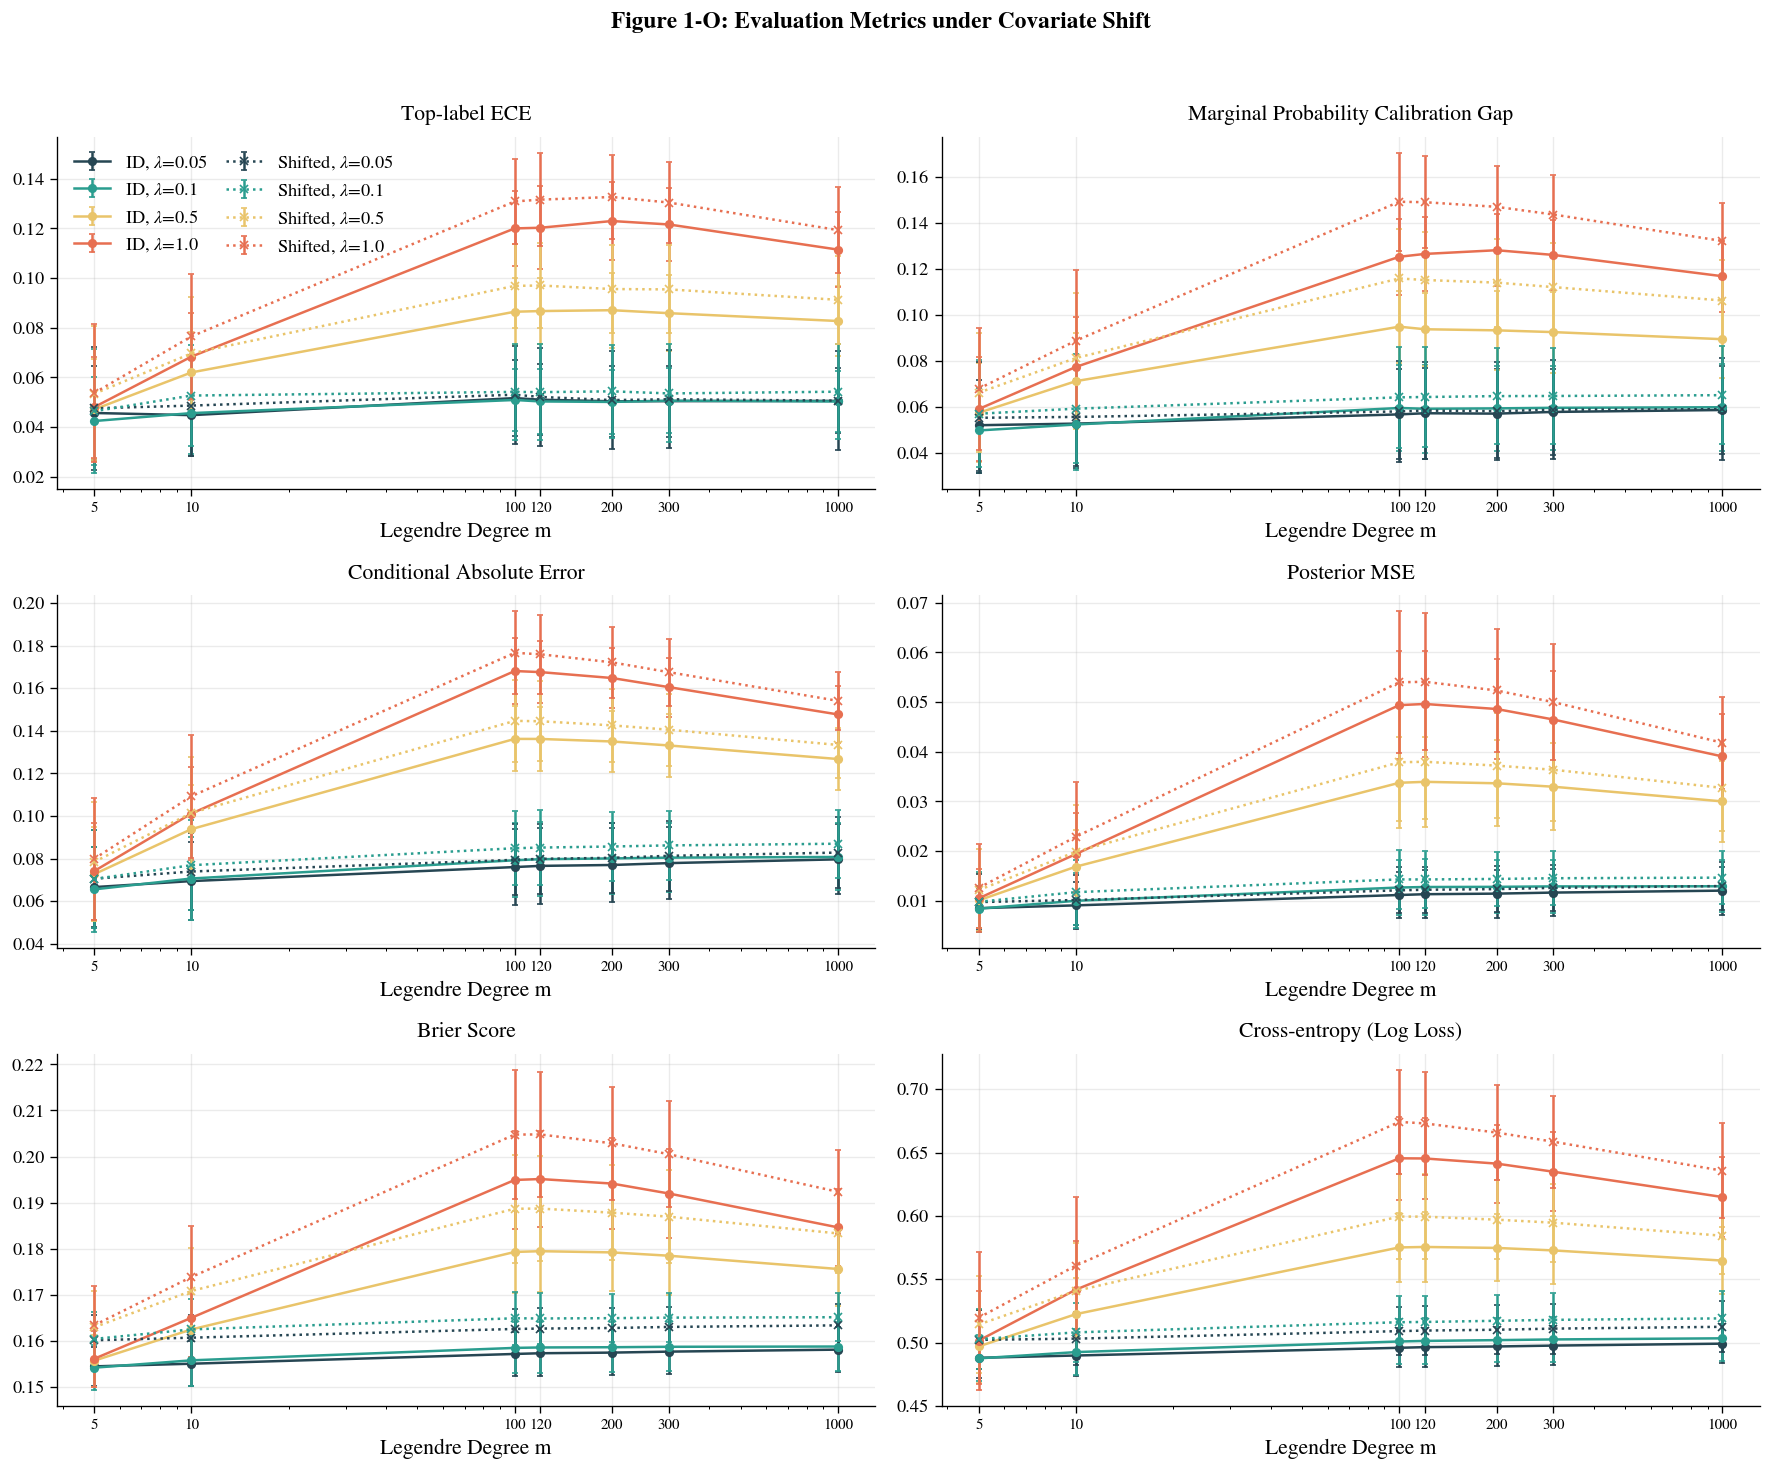

In [18]:
plot_metrics = [
    ("ece_top", "Top-label ECE"),
    ("marginal_calibration_gap", "Marginal Probability Calibration Gap"),
    ("conditional_abs_error", "Conditional Absolute Error"),
    ("mse_eta", "Posterior MSE"),
    ("brier", "Brier Score"),
    ("cross_entropy", "Cross-entropy (Log Loss)"),
]

fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=False)
split_styles = {
    "id": {"linestyle": "-", "marker": "o", "label": "ID"},
    "shift": {"linestyle": ":", "marker": "x", "label": "Shifted"},
}

for ax,(metric,title) in zip(axes.ravel(),plot_metrics):
    for split in ["id", "shift"]:
        style = split_styles[split]
        for lam in LAMBDAS:
            g = (
                results[(results["split"] == split) & (results["lambda"] == lam)]
                .groupby("m")[metric]
                .agg(["mean", "std"])
                .reindex(CAPACITIES)
            )
            ax.errorbar(
                CAPACITIES,
                g["mean"],
                yerr=g["std"],
                color=PALETTE_LAMBDA[lam],
                linestyle=style["linestyle"],
                marker=style["marker"],
                markersize=4.5,
                linewidth=1.5,
                capsize=2,
                label=f'{style["label"]}, $\\lambda$={lam}',
            )
    ax.set_xscale("log")
    ax.set_xticks(CAPACITIES,labels=[str(x) for x in CAPACITIES])
    ax.set_xlabel("Legendre Degree m", labelpad=4)
    ax.set_title(title, pad=10)
    ax.grid(alpha=.25)
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
    ax.tick_params(axis="x", labelrotation=0, labelsize=9)

axes[0, 0].legend(
    loc="upper left",
    ncol=2,
    frameon=False,
    columnspacing=1.0,
    handlelength=2.0,
)

fig.suptitle("Figure 1-O: Evaluation Metrics under Covariate Shift", y=1.02)
plt.tight_layout()
fig.savefig("Figure_1O_evaluation_metrics.pdf", format="pdf", bbox_inches="tight")
plt.show()


## 8. Interpretation of Results

### 8.1 Experimental Setup and Covariate Shift

The experiment evaluates the effect of end-to-end calibration across seven Legendre capacities ($m \in \{5,10,100,120,200,300,1000\}$) and four objective weights ($\lambda \in \{0.05,0.1,0.5,1.0\}$), averaged over 30 seeds. The predictive loss is cross-entropy, weighted by $\lambda$, while the soft calibration penalty receives weight $1-\lambda$. Thus, $\lambda=1$ is the predictive-only baseline, whereas smaller values place greater emphasis on calibration.

The input distributions confirm that the experiment introduces covariate shift without changing the conditional label mechanism. The ID test inputs have mean approximately $-0.004$, compared with $0.442$ for the shifted inputs. The observed positive-label rates are approximately $0.496$ and $0.688$, respectively. Since the conditional probability function $\eta(x)$ is unchanged, differences between ID and shifted performance arise from the change in the input distribution rather than concept or label shift.

### 8.2 Effect of the Calibration Objective

The results show a consistent advantage for stronger calibration regularization over the predictive-only baseline, particularly at higher model capacities. Across the six evaluation metrics, $\lambda=0.05$ and $\lambda=0.1$ generally produce lower errors than $\lambda=0.5$ and $\lambda=1.0$.

The difference is especially pronounced for capacities of 100 and above. For example, on the ID distribution at $m=100$, top-label ECE decreases from $0.1200$ at $\lambda=1.0$ to $0.0516$ at $\lambda=0.05$. On the shifted distribution, it decreases from $0.1308$ to $0.0530$. This indicates that the calibration-aware objective substantially improves the reliability of predictions relative to the predictive-only baseline in these settings.

The intermediate setting $\lambda=0.5$ generally improves upon $\lambda=1.0$, but it does not match the lower errors achieved with $\lambda=0.05$ or $\lambda=0.1$. The two smaller weights perform similarly overall, with neither uniformly dominating the other across every capacity, distribution, and metric. At $m=5$, for instance, $\lambda=0.1$ achieves the lowest top-label ECE on both ID and shifted data, while $\lambda=0.05$ yields slightly lower posterior MSE and Brier score on ID data.

These results suggest that emphasizing calibration during training is beneficial in this experimental setting. However, the best objective weight depends on the metric and model capacity, rather than following a universal ordering between $\lambda=0.05$ and $\lambda=0.1$.

### 8.3 Effect of Model Capacity

Model capacity strongly affects the predictive-only baseline. At low capacities, the differences between objective weights are relatively modest. As capacity increases, the errors for $\lambda=0.5$ and especially $\lambda=1.0$ generally increase, indicating that the more flexible models are less reliable without sufficient calibration regularization.

For example, ID top-label ECE for the predictive-only baseline increases from $0.0480$ at $m=5$ to $0.1200$ at $m=100$, and remains elevated at larger capacities before decreasing to $0.1115$ at $m=1000$. The corresponding shifted ECE increases from $0.0537$ at $m=5$ to $0.1308$ at $m=100$, and decreases to $0.1193$ at $m=1000$.

By contrast, for $\lambda=0.05$ and $\lambda=0.1$, top-label ECE remains comparatively stable across capacities. The other calibration and posterior-based metrics show a similar broad pattern: the calibration-aware objectives substantially reduce the deterioration observed with increasing capacity, although their errors are not entirely invariant to capacity.

The trends are not strictly monotonic, and the largest capacity is not always the worst-performing model. The evidence therefore supports the more specific conclusion that calibration regularization mitigates the capacity-related deterioration observed in this experiment, rather than that increasing capacity invariably worsens performance.

### 8.4 Agreement Across Evaluation Metrics

The six metrics provide complementary views of model performance.

- **Top-label ECE:** The label-based calibration error generally decreases substantially under stronger calibration regularization, particularly at higher capacities. Because it uses observed labels and confidence bins, it can also reflect finite-sample variability.
- **Marginal probability calibration gap:** This metric compares predicted probabilities with the true posterior $\eta(x)$ within probability bins. Its broad agreement with top-label ECE supports the conclusion that the improvement is not limited to the thresholded classification-confidence diagnostic.
- **Conditional absolute error:** This measures $\mathbb{E}_{Q_X}|p(X)-\eta(X)|$ directly. Its deterioration for higher-capacity predictive-only models and improvement under smaller objective weights indicate that the changes also affect the conditional probability estimates.
- **Posterior MSE:** This measures $\mathbb{E}_{Q_X}(p(X)-\eta(X))^2$. It follows the same broad trend as conditional absolute error, with substantially lower errors for the strongly calibration-regularized models.
- **Brier score:** This evaluates squared error against the observed labels, combining probability-estimation quality with irreducible Bernoulli label noise. It generally improves with stronger calibration regularization in the reported experiments.
- **Cross-entropy (log loss):** This metric also improves markedly at smaller objective weights. For example, at $m=100$, ID cross-entropy decreases from $0.6454$ at $\lambda=1.0$ to $0.4960$ at $\lambda=0.05$, while shifted cross-entropy decreases from $0.6741$ to $0.5091$.

The agreement across these metrics strengthens the overall conclusion that the calibration-aware objective improves more than a single calibration diagnostic. Nevertheless, the metrics are not interchangeable: top-label ECE measures calibration of classification confidence, whereas the posterior-based measures directly quantify discrepancies from the known conditional probability function.

### 8.5 Robustness under Covariate Shift

For all six metrics, the reported robustness gap is defined as the shifted mean minus the ID mean. A positive gap indicates deterioration under the shifted input distribution.

For the lower-weight objectives, the absolute errors generally remain relatively low on both distributions. For example, at $m=1000$ and $\lambda=0.05$, top-label ECE is $0.0505$ on ID data and $0.0506$ on shifted data. The corresponding gap is approximately $0.0001$. At the same capacity with $\lambda=1.0$, ECE increases from $0.1115$ to $0.1193$, giving a gap of $0.0078$.

The other metrics also generally show higher errors under the shifted distribution. At $m=1000$ and $\lambda=1.0$, the marginal calibration gap increases from $0.1167$ to $0.1320$, posterior MSE from $0.0390$ to $0.0418$, Brier score from $0.1846$ to $0.1924$, and cross-entropy from $0.6149$ to $0.6357$.

These results show that the shifted distribution can affect both calibration diagnostics and predictive performance, even though $\eta(x)$ remains unchanged. The magnitude of the shift effect depends on the objective weight, capacity, and metric. A small robustness gap should not be interpreted in isolation: both the ID and shifted absolute errors must be considered, since a model can have a small gap while performing poorly on both distributions.

Moreover, conditional absolute error and posterior MSE are weighted by the test input distribution. Their values can therefore change under covariate shift even when the conditional label mechanism is fixed. This is a distribution-weighting effect, not evidence that the underlying conditional relationship has changed.

### 8.6 Statistical Comparisons Across Seeds

Paired Wilcoxon signed-rank tests compare each of $\lambda=0.05$, $\lambda=0.1$, and $\lambda=0.5$ with the predictive-only baseline $\lambda=1.0$, separately for each capacity, test distribution, and evaluation metric. Bonferroni adjustment is applied across the full set of 252 comparisons.

The corrected results should be interpreted at the level of individual metric, capacity, and distribution combinations. Some comparisons remain statistically significant after correction, while others do not. For example, at $m=5$ on ID data, the top-label ECE comparisons for $\lambda=0.1$ and $\lambda=0.5$ have unadjusted $p$-values below $0.05$, but neither remains significant after the full Bonferroni correction. In contrast, the marginal calibration-gap comparison between $\lambda=0.1$ and $\lambda=1.0$ at the same capacity remains significant after correction.

At larger capacities, many comparisons show much stronger evidence of differences between the calibration-aware objectives and the predictive-only baseline. The statistical results therefore complement the descriptive trends, while also showing that the strength of the evidence depends on the setting.

Statistical significance should not be equated with practical importance, and non-significance after a conservative correction does not establish equivalence. The mean differences, standard deviations, and corrected $p$-values should be considered together.

### 8.7 Overall Conclusion

Across the 30-seed experiment, end-to-end calibration regularization generally improves the six reported evaluation metrics compared with the predictive-only baseline. The benefit is particularly clear at higher capacities, where the baseline exhibits substantially larger calibration errors and posterior probability errors. The smaller objective weights, $\lambda=0.05$ and $\lambda=0.1$, perform best overall, although their relative ordering varies by metric and capacity.

The shifted evaluation confirms that the same conditional label mechanism can yield different performance under a changed input distribution. Calibration-aware training substantially reduces errors on both ID and shifted data, but it does not eliminate every shift-related deterioration.

Taken together, the results support the use of calibration-aware training as a way to improve probability reliability and mitigate capacity-related deterioration in this controlled covariate-shift setting. The conclusions should remain specific to the simulated data-generating process, the tested capacities and objective weights, and the chosen calibration penalty; they do not establish that the same ordering will hold for all datasets or distribution shifts.
